# Aula 14 — Aprendizado de máquina, métricas de desempenho e validação

**Fundamentos de Programação, Dados e Estatística para IA**

Neste notebook vamos:

1. entender o que é um modelo de aprendizado de máquina supervisionado;
2. treinar dois modelos simples: **regressão linear** e **KNN**;
3. avaliar as previsões com a **matriz de confusão** e as métricas de classificação;
4. discutir **limiar**, **referência simples** e métricas de regressão (**MAE** e **MSE**);
5. separar **treino e teste**, evitar **vazamento** e usar **validação cruzada**.

> A seção de dados usa uma **base simulada** do caso-guia de readmissão hospitalar, para que todos obtenham os mesmos números dos slides. No final, troque pela base real da disciplina e repita a análise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    mean_absolute_error, mean_squared_error
)

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid")

## 0. A base do caso-guia (simulada)

Cada linha é um paciente que recebeu alta. Queremos prever **readmissão em até 30 dias** (`readmissao_30d`: 1 = sim, 0 = não).

In [2]:
rng = np.random.default_rng(42)
n = 500
idade = rng.normal(64, 13, n).round().clip(18, 98)
tempo = rng.gamma(2.2, 2.6, n).round().clip(1, 40)
comorb = rng.poisson(1.6, n)
z = -2.2 + 0.035 * (idade - 64) + 0.12 * (tempo - 5.7) + 0.45 * (comorb - 1.6)
readm = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)

df = pd.DataFrame({
    "idade": idade,
    "tempo_internacao": tempo,
    "numero_comorbidades": comorb,
    "readmissao_30d": readm,
})

# Para usar a base real da disciplina, substitua as linhas acima por:
# df = pd.read_csv("caminho/para/base_readmissao.csv")

df.head()

,idade,tempo_internacao,numero_comorbidades,readmissao_30d
0,68.0,11.0,1,0
1,50.0,3.0,1,0
2,74.0,20.0,4,1
3,76.0,3.0,5,0
4,39.0,1.0,0,0


In [27]:
print("Pacientes:", len(df))
print("Proporção de readmitidos:", df["readmissao_30d"].mean())

Pacientes: 500
Proporção de readmitidos: 0.128


**Note:** só cerca de 13% dos pacientes foram readmitidos. As classes são **desbalanceadas**, e isso vai importar muito na hora de avaliar.

---
# 01 · Aprendizado de máquina

### O vocabulário: X, y, modelo e previsão

- **X (features):** variáveis de entrada, conhecidas no momento da previsão;
- **y (alvo):** o que queremos prever;
- **modelo:** a regra que liga X a y, ajustada com exemplos;
- **ŷ (previsão):** o que o modelo diz para um paciente novo.

In [28]:
X = df[["idade", "tempo_internacao", "numero_comorbidades"]]   # duplo colchete: tabela
y = df["readmissao_30d"]                                        # uma coluna

print("X:", X.shape, " y:", y.shape)

X: (500, 3)  y: (500,)


### Regressão × classificação

| Tarefa | Alvo | Exemplo | Como avaliar |
|---|---|---|---|
| Regressão | número | dias de internação | MAE, MSE |
| Classificação | categoria | readmitiu ou não | matriz de confusão, acurácia, sensibilidade… |

Todo modelo do scikit-learn segue o mesmo padrão:

```python
modelo.fit(X_treino, y_treino)      # aprende
y_pred = modelo.predict(X_teste)    # prevê
```

## Exemplo 1 — Regressão linear

Os 14 pacientes do slide: idade × dias de internação.

In [5]:
rl = pd.DataFrame({
    "idade": [34, 41, 45, 50, 53, 58, 61, 64, 68, 72, 75, 79, 83, 87],
    "dias":  [ 2,  3,  3,  3,  4,  4,  5,  7,  5,  6,  7,  8,  8,  7],
})

modelo_rl = LinearRegression()
modelo_rl.fit(rl[["idade"]], rl["dias"])

b0 = modelo_rl.intercept_
b1 = modelo_rl.coef_[0]
print(f"ŷ = {b0:.2f} + {b1:.3f} × idade")

novo = pd.DataFrame({"idade": [70]})
print("Previsão para 70 anos:", round(float(modelo_rl.predict(novo)[0]), 2), "dias")

ŷ = -2.14 + 0.117 × idade
Previsão para 70 anos: 6.06 dias


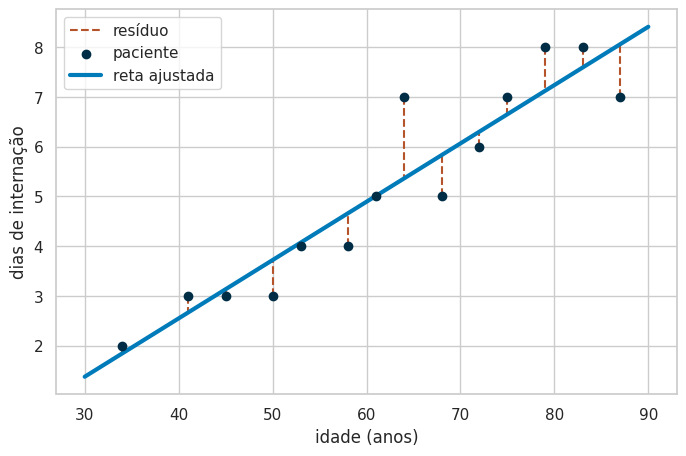

MAE nos próprios dados: 0.539
MSE nos próprios dados: 0.483


In [6]:
rl["previsto"] = modelo_rl.predict(rl[["idade"]])
rl["residuo"] = rl["dias"] - rl["previsto"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.vlines(rl["idade"], rl["dias"], rl["previsto"], colors="#B5532A", linestyles="dashed", label="resíduo")
ax.scatter(rl["idade"], rl["dias"], color="#002D46", zorder=3, label="paciente")
xs = np.array([30, 90])
ax.plot(xs, b0 + b1 * xs, color="#007BBA", lw=3, label="reta ajustada")
ax.set_xlabel("idade (anos)"); ax.set_ylabel("dias de internação"); ax.legend()
plt.show()

print("MAE nos próprios dados:", round(mean_absolute_error(rl["dias"], rl["previsto"]), 3))
print("MSE nos próprios dados:", round(mean_squared_error(rl["dias"], rl["previsto"]), 3))

### Como a reta é encontrada? (a animação do slide)

O ajuste busca os valores de b₀ e b₁ com o **menor MSE**. O código abaixo começa com uma reta errada e a corrige passo a passo (**gradiente descendente**). O `LinearRegression` chega à mesma reta com uma conta direta, mas essa ideia de “corrigir aos poucos” é a que treina a maioria dos modelos, inclusive redes neurais.

In [7]:
x, yv = rl["idade"].to_numpy(), rl["dias"].to_numpy()
z = (x - x.mean()) / x.std()           # idade padronizada: facilita os passos
a, b = 2.0, -1.2                      # reta inicial (errada de propósito)
taxa = 0.08

for passo in range(401):
    erro = (a + b * z) - yv
    if passo in [0, 5, 20, 50, 100, 400]:
        print(f"passo {passo:3d} · MSE = {np.mean(erro**2):.3f}")
    a -= taxa * 2 * erro.mean()
    b -= taxa * 2 * (erro * z).mean()

b1_gd = b / x.std()
b0_gd = a - b1_gd * x.mean()
print(f"\nReta final: ŷ = {b0_gd:.2f} + {b1_gd:.3f} × idade")

passo   0 · MSE = 19.550
passo   5 · MSE = 3.818
passo  20 · MSE = 0.501
passo  50 · MSE = 0.483
passo 100 · MSE = 0.483
passo 400 · MSE = 0.483

Reta final: ŷ = -2.14 + 0.117 × idade


## Exemplo 2 — KNN (k vizinhos mais próximos)

Para prever um paciente novo, o KNN olha os **k pacientes mais parecidos** e faz uma **votação**. Usamos os 26 pacientes do slide, com as duas variáveis na mesma escala (0 a 1).

In [8]:
knn_ex = pd.DataFrame({
    "idade": [81, 44, 49, 52, 49, 80, 84, 69, 42, 44, 56, 62, 71, 64, 53, 48, 75, 77, 41, 45, 63, 59, 85, 66, 61, 61],
    "dias":  [10, 9, 3, 11, 11, 14, 12, 4, 5, 10, 10, 10, 13, 5, 14, 1, 2, 14, 14, 5, 2, 5, 1, 13, 10, 9],
    "readmitiu": [1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1],
})
novo = {"idade": 56, "dias": 7}

# colocar na mesma escala (0 a 1) e medir a distância euclidiana
esc_idade = (knn_ex["idade"] - 40) / 50
esc_dias = (knn_ex["dias"] - 1) / 13
knn_ex["distancia"] = np.sqrt((esc_idade - (novo["idade"] - 40) / 50) ** 2 +
                              (esc_dias - (novo["dias"] - 1) / 13) ** 2)

vizinhos = knn_ex.sort_values("distancia")
vizinhos.head(5)

,idade,dias,readmitiu,distancia
21,59,5,0,0.165
25,61,9,1,0.183
13,64,5,0,0.222
10,56,10,1,0.231
24,61,10,1,0.252


In [9]:
for k in [1, 5, 11]:
    votos = vizinhos.head(k)["readmitiu"]
    previsao = "readmite" if votos.mean() > 0.5 else "não readmite"
    print(f"k = {k:2d}: {votos.sum()} de {k} readmitiram → {previsao}")

k =  1: 0 de 1 readmitiram → não readmite
k =  5: 3 de 5 readmitiram → readmite
k = 11: 3 de 11 readmitiram → não readmite


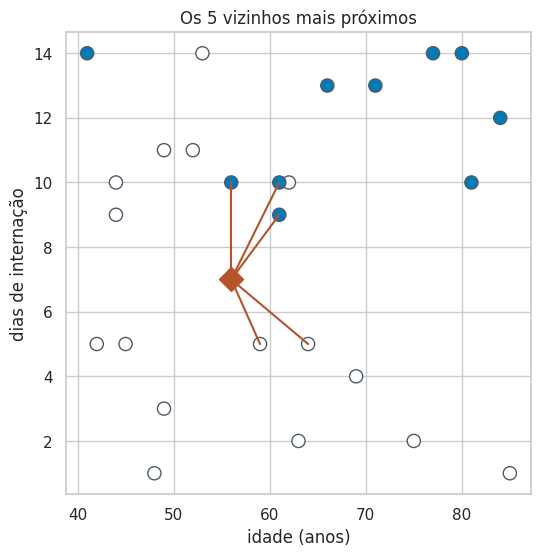

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
cores = knn_ex["readmitiu"].map({1: "#007BBA", 0: "white"})
ax.scatter(knn_ex["idade"], knn_ex["dias"], c=cores, edgecolors="#4F5B66", s=90, label="pacientes")
top5 = vizinhos.head(5)
for _, p in top5.iterrows():
    ax.plot([novo["idade"], p["idade"]], [novo["dias"], p["dias"]], color="#B5532A")
ax.scatter([novo["idade"]], [novo["dias"]], marker="D", color="#B5532A", s=150, label="paciente novo")
ax.set_xlabel("idade (anos)"); ax.set_ylabel("dias de internação")
ax.set_title("Os 5 vizinhos mais próximos")
plt.show()

### KNN na base inteira

O `StandardScaler` coloca as variáveis na mesma escala. O `make_pipeline` garante que ele aprenda média e desvio **só com o treino** (evita vazamento, seção 05).

In [11]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo.fit(X_treino, y_treino)
y_pred = modelo.predict(X_teste)

print("Primeiras previsões:", y_pred[:20])

Primeiras previsões: [0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 1 0 0]


### O que esses números escondem?

Antes de aprender as métricas, compare três valores de k. Qual modelo você escolheria?

In [12]:
linhas = []
for k in [1, 5, 15]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_treino, y_treino)
    p = m.predict(X_teste)
    linhas.append({
        "modelo": f"KNN, k = {k}",
        "acurácia no treino": accuracy_score(y_treino, m.predict(X_treino)),
        "acurácia no teste": accuracy_score(y_teste, p),
        "readmitidos encontrados": f"{((p == 1) & (y_teste == 1)).sum()} de {y_teste.sum()}",
    })
linhas.append({"modelo": "Sempre 'não'", "acurácia no treino": np.nan,
               "acurácia no teste": accuracy_score(y_teste, np.zeros(len(y_teste))),
               "readmitidos encontrados": f"0 de {y_teste.sum()}"})
pd.DataFrame(linhas)

,modelo,acurácia no treino,acurácia no teste,readmitidos encontrados
0,"KNN, k = 1",0.988,0.81,5 de 13
1,"KNN, k = 5",0.885,0.85,1 de 13
2,"KNN, k = 15",0.882,0.87,0 de 13
3,Sempre 'não',NaN,0.87,0 de 13


Dois problemas aparecem:

1. **Treino engana:** com k = 1 o modelo quase “decora” o treino.
2. **Acurácia engana:** a maior acurácia é de um modelo que não encontra nenhum readmitido.

---
# 02 · A matriz de confusão

Exemplo do slide com 12 pacientes. Classe positiva: **readmissão = 1**.

In [13]:
y_true = [0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1]
y_pred_ex = [0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0]

cm = confusion_matrix(y_true, y_pred_ex, labels=[0, 1])
print(cm)

tn, fp, fn, tp = cm.ravel()
print("TN =", tn, " FP =", fp, " FN =", fn, " TP =", tp)

[[6 1]
 [2 3]]
TN = 6  FP = 1  FN = 2  TP = 3


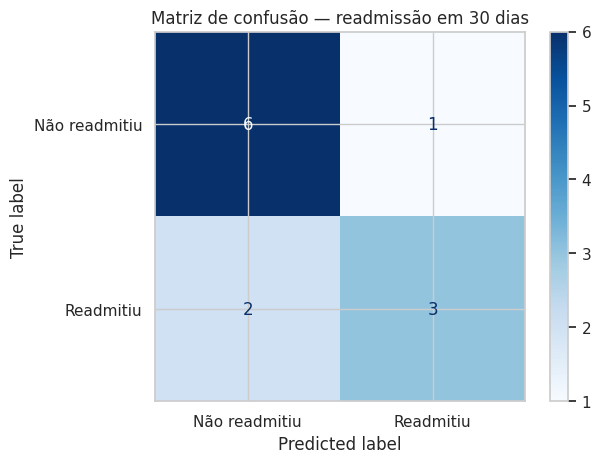

In [14]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Não readmitiu", "Readmitiu"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão — readmissão em 30 dias")
plt.show()

> No scikit-learn: **linhas = valor verdadeiro**, **colunas = previsão**. Sempre confira os eixos.

---
# 03 · Métricas de classificação

| Métrica | Fórmula | Pergunta |
|---|---|---|
| Acurácia | (TP + TN) / total | Que fração foi classificada corretamente? |
| Sensibilidade (recall) | TP / (TP + FN) | Entre os readmitidos, quantos encontramos? |
| Especificidade | TN / (TN + FP) | Entre os não readmitidos, quantos reconhecemos? |
| Precisão | TP / (TP + FP) | Entre os alertas, quantos estavam certos? |
| F1 | 2 × P × S / (P + S) | Equilíbrio entre precisão e sensibilidade |

In [15]:
acuracia = accuracy_score(y_true, y_pred_ex)
precisao = precision_score(y_true, y_pred_ex, zero_division=0)
sensibilidade = recall_score(y_true, y_pred_ex)
f1 = f1_score(y_true, y_pred_ex)
especificidade = tn / (tn + fp)            # não há função pronta

print(f"Acurácia:       {acuracia:.3f}")
print(f"Precisão:       {precisao:.3f}")
print(f"Sensibilidade:  {sensibilidade:.3f}")
print(f"Especificidade: {especificidade:.3f}")
print(f"F1-score:       {f1:.3f}")

Acurácia:       0.750
Precisão:       0.750
Sensibilidade:  0.600
Especificidade: 0.857
F1-score:       0.667


In [16]:
print(classification_report(y_true, y_pred_ex, target_names=["Não readmitiu", "Readmitiu"], zero_division=0))

               precision    recall  f1-score   support

Não readmitiu       0.75      0.86      0.80         7
    Readmitiu       0.75      0.60      0.67         5

     accuracy                           0.75        12
    macro avg       0.75      0.73      0.73        12
 weighted avg       0.75      0.75      0.74        12



### Por que a acurácia pode enganar

100 pacientes, 5 readmitidos, e um “sistema” que sempre diz **não readmitirá**:

In [17]:
y_real = [1] * 5 + [0] * 95
y_sempre_nao = [0] * 100
print("Acurácia:", accuracy_score(y_real, y_sempre_nao))
print("Sensibilidade:", recall_score(y_real, y_sempre_nao, zero_division=0))

Acurácia: 0.95
Sensibilidade: 0.0


### As métricas do KNN (k = 5) na base simulada

In [18]:
cm_knn = confusion_matrix(y_teste, y_pred, labels=[0, 1])
tn_k, fp_k, fn_k, tp_k = cm_knn.ravel()
print(cm_knn)
print(f"Acurácia:       {accuracy_score(y_teste, y_pred):.3f}")
print(f"Sensibilidade:  {recall_score(y_teste, y_pred):.3f}")
print(f"Especificidade: {tn_k / (tn_k + fp_k):.3f}")
print(f"Precisão:       {precision_score(y_teste, y_pred, zero_division=0):.3f}")

[[84  3]
 [12  1]]
Acurácia:       0.850
Sensibilidade:  0.077
Especificidade: 0.966
Precisão:       0.250


**Pergunta:** num alerta para telefonema pós-alta (baixo custo), qual dessas métricas importa mais? E numa intervenção invasiva?

---
# 04 · Limiar, referência simples e regressão

### Limiar de decisão

O KNN também devolve uma **fração de votos** (um escore). A classe final depende do **limiar**.

In [19]:
probabilidades = [0.12, 0.31, 0.82, 0.47, 0.71, 0.66, 0.18, 0.55]
for limiar in [0.3, 0.5, 0.7]:
    predicoes = [1 if p >= limiar else 0 for p in probabilidades]
    print(f"limiar {limiar}: {predicoes} → {sum(predicoes)} alertas")

limiar 0.3: [0, 1, 1, 1, 1, 1, 0, 1] → 6 alertas
limiar 0.5: [0, 0, 1, 0, 1, 1, 0, 1] → 4 alertas
limiar 0.7: [0, 0, 1, 0, 1, 0, 0, 0] → 2 alertas


In [20]:
escore = modelo.predict_proba(X_teste)[:, 1]     # fração de vizinhos readmitidos

linhas = []
for limiar in [0.2, 0.4, 0.6]:
    p = (escore >= limiar).astype(int)
    linhas.append({"limiar": limiar,
                   "alertas": p.sum(),
                   "sensibilidade": recall_score(y_teste, p),
                   "precisão": precision_score(y_teste, p, zero_division=0)})
pd.DataFrame(linhas)

,limiar,alertas,sensibilidade,precisão
0,0.2,42,0.615,0.190
1,0.4,14,0.154,0.143
2,0.6,4,0.077,0.250


Limiar menor → mais alertas, mais sensibilidade, mais falsos positivos. A escolha depende do custo do erro — e **não** deve ser feita olhando o conjunto de teste.

### Referência simples (baseline)

In [21]:
pred_baseline = [0] * len(y_true)                # sempre a classe mais frequente
print("Baseline  · acurácia:", round(accuracy_score(y_true, pred_baseline), 2),
      "· sensibilidade:", recall_score(y_true, pred_baseline, zero_division=0))
print("Sistema   · acurácia:", round(accuracy_score(y_true, y_pred_ex), 2),
      "· sensibilidade:", recall_score(y_true, y_pred_ex))

Baseline  · acurácia: 0.58 · sensibilidade: 0.0
Sistema   · acurácia: 0.75 · sensibilidade: 0.6


### Métricas de regressão: MAE e MSE

In [22]:
y_true_reg = [3.0, 5.0, 8.0, 4.0, 10.0, 6.0]
y_pred_reg = [3.5, 4.2, 7.1, 5.0, 8.7, 6.4]

tabela = pd.DataFrame({"y": y_true_reg, "ŷ": y_pred_reg})
tabela["erro"] = tabela["y"] - tabela["ŷ"]
tabela["|erro|"] = tabela["erro"].abs()
tabela["erro²"] = tabela["erro"] ** 2
display(tabela)

print("MAE =", round(mean_absolute_error(y_true_reg, y_pred_reg), 3))
print("MSE =", round(mean_squared_error(y_true_reg, y_pred_reg), 3))

,y,ŷ,erro,|erro|,erro²
0,3.0,3.5,-0.5,0.5,0.25
1,5.0,4.2,0.8,0.8,0.64
2,8.0,7.1,0.9,0.9,0.81
3,4.0,5.0,-1.0,1.0,1.00
4,10.0,8.7,1.3,1.3,1.69
5,6.0,6.4,-0.4,0.4,0.16


MAE = 0.817
MSE = 0.758


O MAE fica na unidade da variável (dias); o MSE eleva ao quadrado e dá mais peso aos erros grandes.

---
# 05 · Treino, teste e validação

### Por que separar?

In [23]:
print("Treino:", X_treino.shape[0], "pacientes · readmitidos:", round(y_treino.mean(), 3))
print("Teste: ", X_teste.shape[0], "pacientes · readmitidos:", round(y_teste.mean(), 3))

Treino: 400 pacientes · readmitidos: 0.128
Teste:  100 pacientes · readmitidos: 0.13


O `stratify=y` manteve a mesma proporção de readmitidos nos dois conjuntos. O conjunto de teste **não** participa de nenhuma decisão do desenvolvimento.

### Vazamento de dados: o jeito errado e o jeito certo de padronizar

In [24]:
# ERRADO: o scaler aprende média e desvio com TODOS os dados (inclui o teste)
scaler_errado = StandardScaler().fit(X)

# CERTO: dentro do pipeline, o scaler aprende só no treino
modelo_certo = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
modelo_certo.fit(X_treino, y_treino)
print("Média aprendida no treino:", modelo_certo[0].mean_.round(2))
print("Média de todos os dados:  ", scaler_errado.mean_.round(2))

Média aprendida no treino: [63.5   5.71  1.64]
Média de todos os dados:   [63.81  5.59  1.63]


### Validação cruzada

Uma única divisão pode enganar. Com 5 blocos, cada rodada valida em um bloco diferente.

In [25]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_cv = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

sens = cross_val_score(modelo_cv, X_treino, y_treino, cv=cv, scoring="recall")
acc = cross_val_score(modelo_cv, X_treino, y_treino, cv=cv, scoring="accuracy")

print("Acurácia por rodada:     ", acc.round(3), "→ média", acc.mean().round(3))
print("Sensibilidade por rodada:", sens.round(3), "→ média", sens.mean().round(3))

Acurácia por rodada:      [0.875 0.875 0.888 0.875 0.875] → média 0.878
Sensibilidade por rodada: [0.1   0.2   0.1   0.1   0.091] → média 0.118


In [26]:
resultados = []
for k in [1, 3, 5, 9, 15]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    s = cross_val_score(m, X_treino, y_treino, cv=cv, scoring="recall")
    resultados.append({"k": k, "sensibilidade média": s.mean(), "desvio entre rodadas": s.std()})
pd.DataFrame(resultados)

,k,sensibilidade média,desvio entre rodadas
0,1,0.293,0.053
1,3,0.098,0.063
2,5,0.118,0.041
3,9,0.118,0.075
4,15,0.020,0.040
